In [ ]:
"""
Minimal script: fetch GFS for a single point and print a small summary table.

- Relies on helper functions in ../functions.py (get_latest_forecast_cycle,
  calculate_forecast_range, convert_time_to_datetime64).
- Uses FastHerbie to request fields.
- Prints a 1-row table (model = GFS) showing High/Low (°F), Precip (in), Wind (kt), Init, Valid range.
"""
from functions import *   # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import numpy as np
import xarray as xr
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# single point (longitude, latitude)
cityName = "Loveland, CO (KFNL)"
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})

print("Fetching GFS data...")

# determine latest cycle & forecast range for GFS
init_gfs = get_latest_forecast_cycle(model="GFS")
fxx_gfs = calculate_forecast_range(init_gfs, model="GFS")

# request fields (product string may vary by deployment; adjust if needed)
H = FastHerbie([init_gfs], model="gfs", product="pgrb2.0p25", fxx=fxx_gfs)

# 2 m temperature -> convert K to °F
t2m = H.xarray("TMP:2 m above", backend_kwargs={'decode_times': False}
                ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)[1:]  # skip first timestep which is included for precip only
t2m_f = (t2m - 273.15) * 9.0/5.0 + 32.0
tmax_gfs = float(t2m_f.max().values)
tmin_gfs = float(t2m_f.min().values)
init_times_gfs = convert_time_to_datetime64(t2m.time.values)
valid_times_gfs = convert_time_to_datetime64(t2m.valid_time.values)

# wind components -> magnitude (m/s -> kt)
u10 = H.xarray("UGRD:10 m above ground", backend_kwargs={'decode_times': False}
                ).herbie.pick_points(points, method="nearest")['u10'][1:]  # skip first timestep which is included for precip only
v10 = H.xarray("VGRD:10 m above ground", backend_kwargs={'decode_times': False}
                ).herbie.pick_points(points, method="nearest")['v10'][1:]  # skip first timestep which is included for precip only
wind_max_kt = float((np.sqrt(u10**2 + v10**2)).max().values) * 1.94384

# total precipitation (sum over steps) -> convert mm -> inches
# tp = H.xarray(":tp:", backend_kwargs={'decode_times': False}
#                 ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
# precip_in = float(tp.sum().values) * 0.0393701
# Total precipitation from APCP (convert mm -> in); compute 24h accumulation as in prior script
tp = H.xarray(":APCP:surface:0-*", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
tp = tp * 0.0393701   # mm -> inches (1 mm -> 0.0393701 in)

# Subtract first timestep to get accumulation over the requested period (as in original)
tp = tp[1:] - tp[0]
precip = float(tp.max().values)

# build and print a simple table using pandas for formatting
df = pd.DataFrame({
    "Model": ["GFS"],
    "High (°F)": [round(tmax_gfs,2)],
    "Low (°F)": [round(tmin_gfs,2)],
    "Precipitation (in)": [round(precip,3)],
    "Wind Speed (kt)": [round(wind_max_kt,2)],
    "Model Init": [pd.Timestamp(init_times_gfs[0]).isoformat() if hasattr(init_times_gfs, "__len__") else str(init_times_gfs)],
    "Valid Range": [f"{valid_times_gfs[0]} - {valid_times_gfs[-1]}"]
})

title = f"Forecasting for {cityName}"
print(title)
print(df.to_string(index=False))


Fetching GFS data...
Forecasting for Loveland, CO (KFNL)
Model  High (°F)  Low (°F)  Precipitation (in)  Wind Speed (kt)    Model Init                   Valid Range
  GFS      72.64     53.69                 0.0             8.39 2025-09-04T12 2025-09-05T06 - 2025-09-06T03


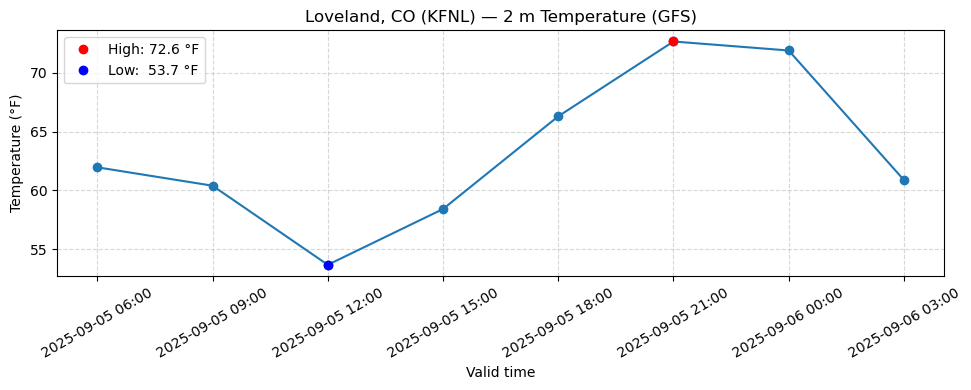

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

times = pd.to_datetime(valid_times_gfs)  # numpy.datetime64 -> DatetimeIndex
temps = t2m_f.values  # Fahrenheit values

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(times, temps, marker='o', linestyle='-')

# highlight max/min
idx_max = int(np.nanargmax(temps))
idx_min = int(np.nanargmin(temps))
ax.plot(times[idx_max], temps[idx_max], 'ro', label=f"High: {temps[idx_max]:.1f} °F")
ax.plot(times[idx_min], temps[idx_min], 'bo', label=f"Low:  {temps[idx_min]:.1f} °F")

ax.set_title(f"{cityName} — 2 m Temperature (GFS)")
ax.set_xlabel("Valid time")
ax.set_ylabel("Temperature (°F)")
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=30)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

In [16]:
u10 = H.xarray("UGRD:10 m above ground", backend_kwargs={'decode_times': False}
                ).herbie.pick_points(points, method="nearest")['u10']
v10 = H.xarray("VGRD:10 m above ground", backend_kwargs={'decode_times': False}
                ).herbie.pick_points(points, method="nearest")['v10']
wind10 = np.sqrt(u10**2 + v10**2)


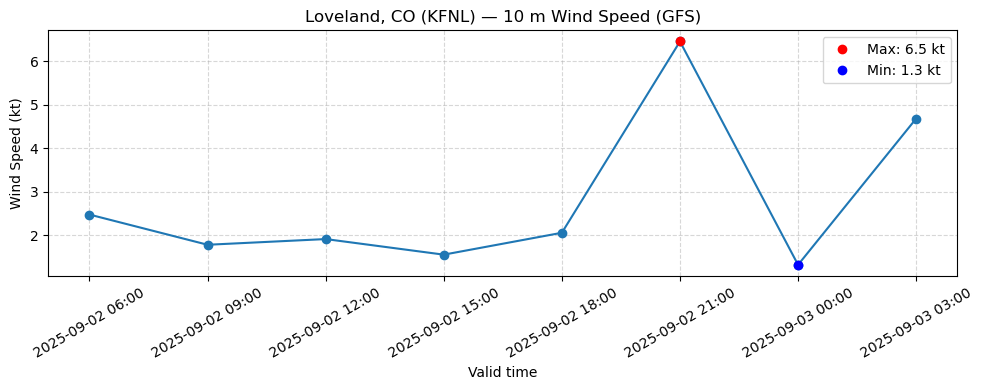

In [20]:
times = pd.to_datetime(valid_times_gfs)  # numpy.datetime64 -> DatetimeIndex

# extract wind at point 0 (m/s) and convert to knots
wind_ms = wind10.sel(point=0).values.flatten()
wind_kt = wind_ms * 1.94384

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(times, wind_kt, marker='o', linestyle='-')

# highlight max/min
idx_max = int(np.nanargmax(wind_kt))
idx_min = int(np.nanargmin(wind_kt))
ax.plot(times[idx_max], wind_kt[idx_max], 'ro', label=f"Max: {wind_kt[idx_max]:.1f} kt")
ax.plot(times[idx_min], wind_kt[idx_min], 'bo', label=f"Min: {wind_kt[idx_min]:.1f} kt")

ax.set_title(f"{cityName} — 10 m Wind Speed (GFS)")
ax.set_xlabel("Valid time")
ax.set_ylabel("Wind Speed (kt)")
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=30)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

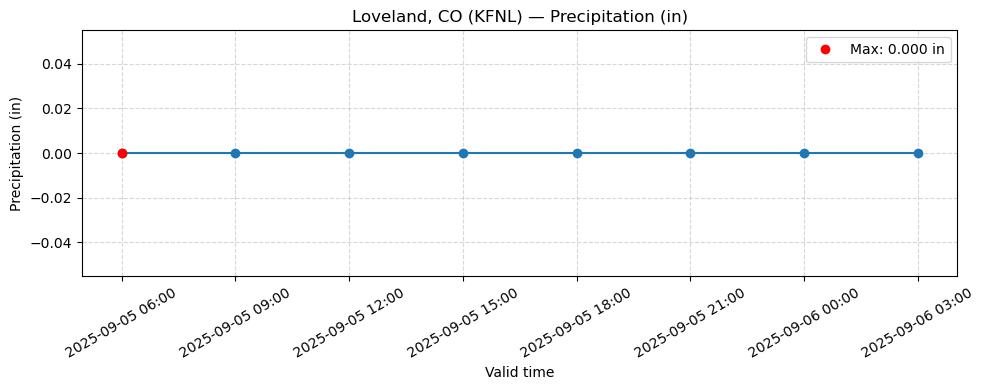

In [8]:
# precipitation time series (tp is already in inches and was computed as tp = tp[1:] - tp[0])
times_precip = times   # tp has length 7, align with times[1:]
precip_vals = tp.values.flatten()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(times_precip, precip_vals, marker='o', linestyle='-')

# highlight max
idx_max_p = int(np.nanargmax(precip_vals))
ax.plot(times_precip[idx_max_p], precip_vals[idx_max_p], 'ro', label=f"Max: {precip_vals[idx_max_p]:.3f} in")

ax.set_title(f"{cityName} — Precipitation (in)")
ax.set_xlabel("Valid time")
ax.set_ylabel("Precipitation (in)")
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=30)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

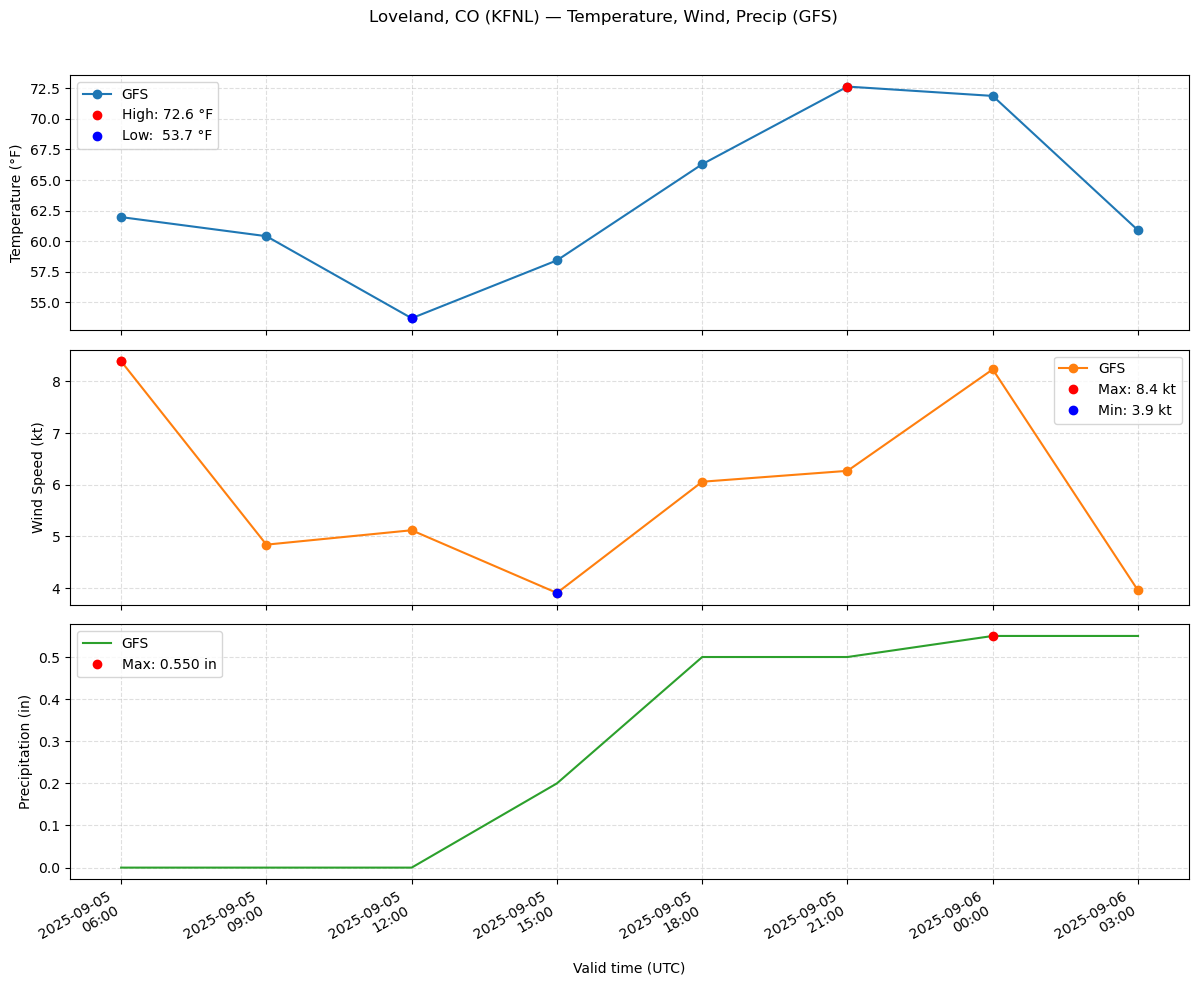

In [13]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# prepare time series (use variables produced earlier in the notebook)
times_temp = pd.to_datetime(valid_times_gfs)      # for temperature and wind
temps = t2m_f.values                              # °F

# wind: ensure wind_kt exists, otherwise compute from u10/v10
try:
    wind_kt  # noqa: F821
except NameError:
    # u10/v10 are xarray DataArrays with point dim; extract and convert
    wind_ms = np.sqrt(u10**2 + v10**2).sel(point=0).values.flatten()
    wind_kt = wind_ms * 1.94384
times_wind = times_temp

# precip: tp was computed as tp = tp[1:] - tp[0], so align with times[1:]
times_precip = times_temp
precip_vals = tp.values.flatten()
precip_vals = [0, 0, 0, 0.2, 0.5, 0.5, 0.55, 0.55]  # example precip values for demonstration

# create a single 3-panel figure (Temperature, Wind, Precip)
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# --- Temperature ---
ax = axes[0]
ax.plot(times_temp, temps, marker='o', linestyle='-', color='C0', label='GFS')
# highlight max/min
if len(temps) > 0:
    idx_max = int(np.nanargmax(temps))
    idx_min = int(np.nanargmin(temps))
    ax.plot(times_temp[idx_max], temps[idx_max], 'ro', label=f"High: {temps[idx_max]:.1f} °F")
    ax.plot(times_temp[idx_min], temps[idx_min], 'bo', label=f"Low:  {temps[idx_min]:.1f} °F")
ax.set_ylabel("Temperature (°F)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# --- Wind ---
ax = axes[1]
ax.plot(times_wind, wind_kt, marker='o', linestyle='-', color='C1', label='GFS')
# highlight max/min
if len(wind_kt) > 0:
    idx_max = int(np.nanargmax(wind_kt))
    idx_min = int(np.nanargmin(wind_kt))
    ax.plot(times_wind[idx_max], wind_kt[idx_max], 'ro', label=f"Max: {wind_kt[idx_max]:.1f} kt")
    ax.plot(times_wind[idx_min], wind_kt[idx_min], 'bo', label=f"Min: {wind_kt[idx_min]:.1f} kt")
ax.set_ylabel("Wind Speed (kt)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# --- Precipitation ---
ax = axes[2]
# use bar for accumulations (better visual for precip)
ax.plot(times_precip, precip_vals, color='C2', label='GFS')
# highlight max
if len(precip_vals) > 0:
    idx_max_p = int(np.nanargmax(precip_vals))
    ax.plot(times_precip[idx_max_p], precip_vals[idx_max_p], 'ro', label=f"Max: {precip_vals[idx_max_p]:.3f} in")
ax.set_ylabel("Precipitation (in)")
ax.set_xlabel("Valid time (UTC)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# format x-axis
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))
plt.setp(axes[-1].xaxis.get_majorticklabels(), rotation=30, ha='right')
plt.suptitle(f"{cityName} — Temperature, Wind, Precip (GFS)", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [14]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def to_1d(x):
    try:
        x = x.sel(point=0)
    except Exception:
        pass
    return np.asarray(x).flatten()

# --- prepare time series for each model ---
times_hrrr = pd.to_datetime(valid_times_hrrr)
temps_hrrr = to_1d(t2m_hrrr)
wind_hrrr = to_1d(si10_hrrr) * 1.94384
precip_hrrr = to_1d(tp_hrrr)  # already converted to inches and processed earlier

times_ifs = pd.to_datetime(valid_times_ifs)
temps_ifs = to_1d(t2m_ifs)
wind_ifs = to_1d(np.sqrt(u10_ifs**2 + v10_ifs**2)) * 1.94384
# convert IFS tp (mm -> in) and compute accumulation inside the window (match other models)
tp_ifs_in = tp_ifs * 0.0393701
if tp_ifs_in.size >= 2:
    precip_ifs = to_1d(tp_ifs_in[1:] - tp_ifs_in[0])
else:
    precip_ifs = to_1d(tp_ifs_in)

times_gfs = pd.to_datetime(valid_times_gfs)
temps_gfs = to_1d(t2m_f)
wind_gfs = to_1d(np.sqrt(u10**2 + v10**2)) * 1.94384
precip_gfs = to_1d(tp_gfs)  # already converted to inches and processed earlier

# --- create combined 3-panel figure ---
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Temperature
ax = axes[0]
ax.plot(times_hrrr, temps_hrrr, marker='o', linestyle='-', color='C0', label='HRRR')
ax.plot(times_ifs, temps_ifs, marker='o', linestyle='-', color='C1', label='IFS')
ax.plot(times_gfs, temps_gfs, marker='o', linestyle='-', color='C2', label='GFS')
ax.set_ylabel("Temperature (°F)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# Wind
ax = axes[1]
ax.plot(times_hrrr, wind_hrrr, marker='o', linestyle='-', color='C0', label='HRRR')
ax.plot(times_ifs, wind_ifs, marker='o', linestyle='-', color='C1', label='IFS')
ax.plot(times_gfs, wind_gfs, marker='o', linestyle='-', color='C2', label='GFS')
ax.set_ylabel("Wind Speed (kt)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# Precipitation (use bars for clarity)
ax = axes[2]
# use a small width; matplotlib will align bars by datetime
ax.bar(times_hrrr, precip_hrrr, width=0.03, label='HRRR', color='C0', alpha=0.6)
ax.bar(times_ifs, precip_ifs, width=0.03, label='IFS', color='C1', alpha=0.6)
ax.bar(times_gfs, precip_gfs, width=0.03, label='GFS', color='C2', alpha=0.6)
ax.set_ylabel("Precipitation (in)")
ax.set_xlabel("Valid time (UTC)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

# format x-axis
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d\n%H:%M'))
plt.setp(axes[-1].xaxis.get_majorticklabels(), rotation=30, ha='right')
plt.suptitle(f"{cityName} — Temperature, Wind, Precip", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])

# save and close
fig.savefig(img_path, dpi=150)
plt.close(fig)
print(f"Wrote {img_path}")


NameError: name 'valid_times_hrrr' is not defined